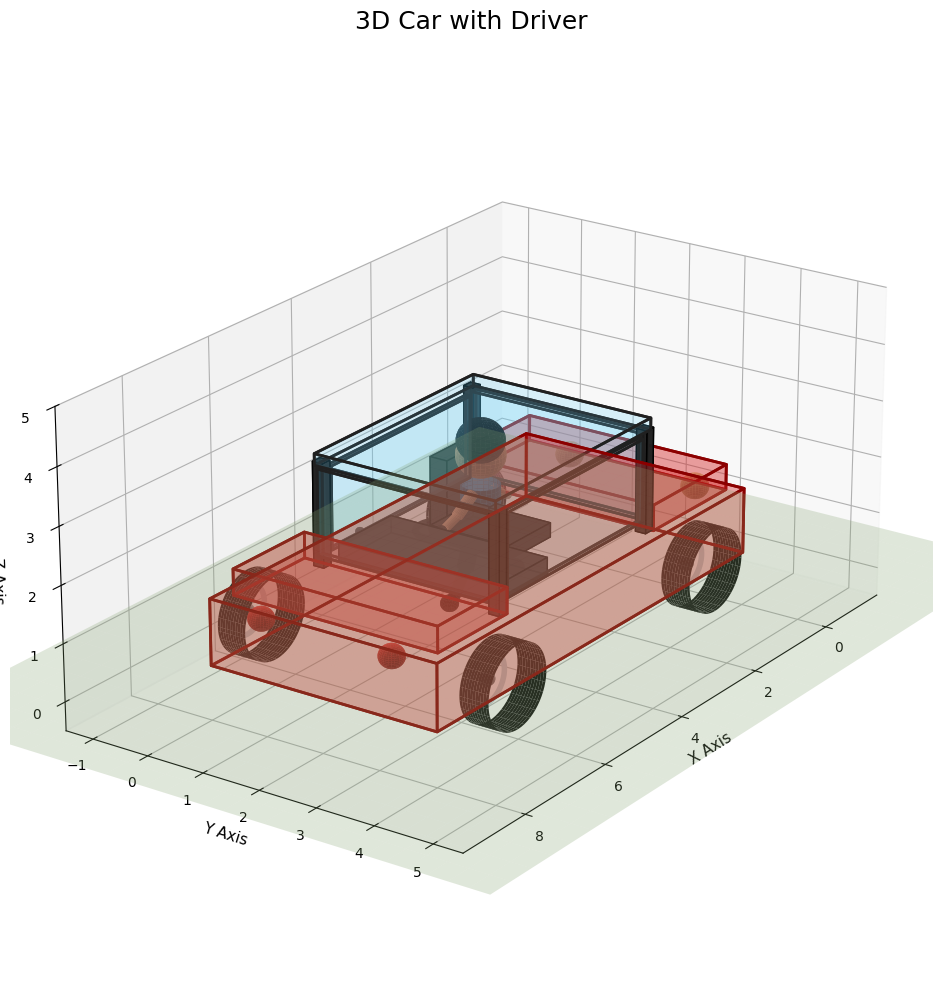

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection='3d')

CAR_RED = '#D62828'
DARK_RED = '#8B0000'
GLASS = '#67D5FF'
FRAME = '#202020'
TIRE = '#151515'
RIM = '#BFC7CE'
SKIN = '#F2B28D'
SHIRT = '#2471A3'
PANTS = '#17202A'
SHOE = '#111111'
SEAT = '#202020'
DASHBOARD = '#252525'
HEADLIGHT = '#FFF2A6'
TAIL_LIGHT = '#FF3030'
GROUND = '#A9D18E'


def draw_box(origin, size, color, alpha=1.0, edgecolor='black', linewidth=1.0):
    x, y, z = origin
    dx, dy, dz = size

    vertices = np.array([
        [x, y, z],
        [x + dx, y, z],
        [x + dx, y + dy, z],
        [x, y + dy, z],
        [x, y, z + dz],
        [x + dx, y, z + dz],
        [x + dx, y + dy, z + dz],
        [x, y + dy, z + dz]
    ])

    faces = [
        [vertices[0], vertices[1], vertices[2], vertices[3]],
        [vertices[4], vertices[5], vertices[6], vertices[7]],
        [vertices[0], vertices[1], vertices[5], vertices[4]],
        [vertices[1], vertices[2], vertices[6], vertices[5]],
        [vertices[2], vertices[3], vertices[7], vertices[6]],
        [vertices[3], vertices[0], vertices[4], vertices[7]]
    ]

    poly = Poly3DCollection(
        faces,
        facecolors=color,
        edgecolors=edgecolor,
        linewidths=linewidth,
        alpha=alpha
    )
    ax.add_collection3d(poly)


def draw_sphere(center, radius, color, alpha=1.0):
    u = np.linspace(0, 2 * np.pi, 32)
    v = np.linspace(0, np.pi, 20)

    x = radius * np.outer(np.cos(u), np.sin(v)) + center[0]
    y = radius * np.outer(np.sin(u), np.sin(v)) + center[1]
    z = radius * np.outer(np.ones(np.size(u)), np.cos(v)) + center[2]

    ax.plot_surface(
        x, y, z,
        color=color,
        alpha=alpha,
        linewidth=0,
        shade=True
    )


def draw_cylinder_between(start, end, radius, color, alpha=1.0):
    start = np.array(start, dtype=float)
    end = np.array(end, dtype=float)

    direction = end - start
    length = np.linalg.norm(direction)

    if length == 0:
        return

    direction /= length

    theta = np.linspace(0, 2 * np.pi, 24)
    z = np.linspace(0, length, 12)
    theta_grid, z_grid = np.meshgrid(theta, z)

    circle_x = radius * np.cos(theta_grid)
    circle_y = radius * np.sin(theta_grid)

    if abs(direction[2]) < 0.9:
        temp = np.array([0, 0, 1])
    else:
        temp = np.array([1, 0, 0])

    u = np.cross(direction, temp)
    u /= np.linalg.norm(u)
    v = np.cross(direction, u)

    points = (
        start.reshape(3, 1, 1)
        + u.reshape(3, 1, 1) * circle_x.reshape(1, *circle_x.shape)
        + v.reshape(3, 1, 1) * circle_y.reshape(1, *circle_y.shape)
        + direction.reshape(3, 1, 1) * z_grid.reshape(1, *z_grid.shape)
    )

    ax.plot_surface(
        points[0],
        points[1],
        points[2],
        color=color,
        alpha=alpha,
        linewidth=0,
        shade=True
    )


def draw_wheel(x, y, z):
    theta = np.linspace(0, 2 * np.pi, 60)
    yy = np.linspace(y - 0.25, y + 0.25, 12)

    theta_grid, yy_grid = np.meshgrid(theta, yy)

    wheel_x = 0.72 * np.cos(theta_grid) + x
    wheel_z = 0.72 * np.sin(theta_grid) + z

    ax.plot_surface(
        wheel_x,
        yy_grid,
        wheel_z,
        color=TIRE,
        shade=True,
        linewidth=0
    )

    ax.plot(
        x + 0.42 * np.cos(theta),
        np.full_like(theta, y - 0.27),
        z + 0.42 * np.sin(theta),
        color=RIM,
        linewidth=4
    )

    draw_sphere((x, y - 0.28, z), 0.12, RIM)


# Car body
draw_box(
    origin=(0, 0, 0.45),
    size=(8, 4, 1.15),
    color=CAR_RED,
    alpha=0.22,
    edgecolor=DARK_RED,
    linewidth=2
)

draw_box(
    origin=(0.2, 0.2, 1.6),
    size=(2.0, 3.6, 0.45),
    color=CAR_RED,
    alpha=0.25,
    edgecolor=DARK_RED,
    linewidth=2
)

draw_box(
    origin=(6.0, 0.2, 1.6),
    size=(1.7, 3.6, 0.45),
    color=CAR_RED,
    alpha=0.25,
    edgecolor=DARK_RED,
    linewidth=2
)

# Glass
draw_box(
    origin=(2.0, 0.4, 3.25),
    size=(4.0, 3.2, 0.20),
    color=GLASS,
    alpha=0.12,
    edgecolor=FRAME,
    linewidth=2
)

draw_box(
    origin=(2.0, 0.45, 1.7),
    size=(0.12, 3.1, 1.5),
    color=GLASS,
    alpha=0.10,
    edgecolor=FRAME,
    linewidth=2
)

draw_box(
    origin=(5.88, 0.45, 1.7),
    size=(0.12, 3.1, 1.5),
    color=GLASS,
    alpha=0.10,
    edgecolor=FRAME,
    linewidth=2
)

draw_box(
    origin=(2.2, 0.40, 1.7),
    size=(3.5, 0.08, 1.45),
    color=GLASS,
    alpha=0.07,
    edgecolor=FRAME,
    linewidth=2
)

draw_box(
    origin=(2.2, 3.52, 1.7),
    size=(3.5, 0.08, 1.45),
    color=GLASS,
    alpha=0.07,
    edgecolor=FRAME,
    linewidth=2
)

# Pillars
pillar_positions = [
    (2.0, 0.35),
    (2.0, 3.47),
    (5.8, 0.35),
    (5.8, 3.47)
]

for x, y in pillar_positions:
    draw_box(
        origin=(x, y, 1.5),
        size=(0.18, 0.18, 1.8),
        color=FRAME,
        alpha=0.85
    )

# Wheels
wheel_positions = [
    (1.4, -0.15, 0.75),
    (6.6, -0.15, 0.75),
    (1.4, 4.15, 0.75),
    (6.6, 4.15, 0.75)
]

for wheel in wheel_positions:
    draw_wheel(*wheel)

# Seats
draw_box(
    origin=(3.0, 1.1, 1.45),
    size=(1.1, 1.4, 0.25),
    color=SEAT,
    alpha=0.95
)

draw_box(
    origin=(3.0, 1.1, 1.65),
    size=(1.1, 0.3, 1.25),
    color=SEAT,
    alpha=0.95
)

# Driver
draw_sphere((3.8, 1.8, 3.0), 0.38, SKIN)
draw_sphere((3.8, 1.8, 3.25), 0.37, FRAME)

draw_cylinder_between(
    (3.8, 1.8, 2.7),
    (3.8, 1.8, 2.5),
    0.11,
    SKIN
)

draw_cylinder_between(
    (3.8, 1.8, 2.5),
    (3.8, 1.8, 1.7),
    0.30,
    SHIRT
)

# Left arm
draw_cylinder_between(
    (3.6, 1.8, 2.4),
    (3.3, 1.8, 2.15),
    0.09,
    SKIN
)

draw_cylinder_between(
    (3.3, 1.8, 2.15),
    (3.1, 1.8, 2.05),
    0.07,
    SKIN
)

# Right arm
draw_cylinder_between(
    (4.0, 1.8, 2.4),
    (4.4, 1.8, 2.15),
    0.09,
    SKIN
)

draw_cylinder_between(
    (4.4, 1.8, 2.15),
    (4.7, 1.8, 2.05),
    0.07,
    SKIN
)

# Left leg
draw_cylinder_between(
    (3.6, 1.8, 1.7),
    (3.35, 1.8, 1.15),
    0.13,
    PANTS
)

draw_cylinder_between(
    (3.35, 1.8, 1.15),
    (3.0, 1.8, 0.75),
    0.09,
    PANTS
)

draw_sphere((2.9, 1.8, 0.7), 0.14, SHOE)

# Right leg
draw_cylinder_between(
    (4.0, 1.8, 1.7),
    (4.2, 1.8, 1.15),
    0.13,
    PANTS
)

draw_cylinder_between(
    (4.2, 1.8, 1.15),
    (4.5, 1.8, 0.75),
    0.09,
    PANTS
)

draw_sphere((4.6, 1.8, 0.7), 0.14, SHOE)

# Steering wheel
theta = np.linspace(0, 2 * np.pi, 100)

steering_x = 4.8 + 0.38 * np.cos(theta)
steering_y = 1.8 + 0.38 * np.sin(theta)
steering_z = np.full_like(theta, 2.05)

ax.plot(
    steering_x,
    steering_y,
    steering_z,
    color=FRAME,
    linewidth=5
)

draw_sphere((4.8, 1.8, 2.05), 0.08, FRAME)

for angle in [0, 2 * np.pi / 3, 4 * np.pi / 3]:
    ax.plot(
        [4.8, 4.8 + 0.32 * np.cos(angle)],
        [1.8, 1.8 + 0.32 * np.sin(angle)],
        [2.05, 2.05],
        color=FRAME,
        linewidth=3
    )

# Dashboard
draw_box(
    origin=(4.4, 0.6, 1.55),
    size=(1.3, 2.8, 0.30),
    color=DASHBOARD,
    alpha=0.85,
    edgecolor='black'
)

# Headlights
draw_sphere((0.05, 0.85, 1.45), 0.22, HEADLIGHT)
draw_sphere((0.05, 3.15, 1.45), 0.22, HEADLIGHT)

# Tail lights
draw_sphere((7.9, 0.85, 1.45), 0.20, TAIL_LIGHT)
draw_sphere((7.9, 3.15, 1.45), 0.20, TAIL_LIGHT)

# Additional frame detail
draw_sphere((4.8, 0.32, 1.65), 0.07, FRAME)

# Ground
xx = np.linspace(-3, 11, 30)
yy = np.linspace(-3, 7, 30)

XX, YY = np.meshgrid(xx, yy)
ZZ = np.full_like(XX, -0.05)

ax.plot_surface(
    XX,
    YY,
    ZZ,
    color=GROUND,
    alpha=0.25,
    linewidth=0
)

# Axes
ax.set_xlim(-1.5, 9.5)
ax.set_ylim(-1.5, 5.5)
ax.set_zlim(-0.5, 5)

ax.set_xlabel("X Axis", fontsize=11)
ax.set_ylabel("Y Axis", fontsize=11)
ax.set_zlabel("Z Axis", fontsize=11)

ax.set_title(
    "3D Car with Driver",
    fontsize=18,
    pad=20
)

ax.view_init(elev=22, azim=35)
ax.set_box_aspect((11, 7, 5))

plt.tight_layout()
plt.show()